# POGOS: SOSSSISSE step-by-step

This is the basic steps to run just the SOSSISSE steps using a POGOS yaml 
file.

This assumes you have run `pogos_setup.py` first to generate the file structure and the yaml file mentioned below.

## Imports and notebook setup

In [1]:
import numpy as np

from sossisse.core import io
from sossisse.core import misc
from sossisse.general import general
from sossisse.general import plots

from pogos.resources import nb_funcs

## Yaml file definition

Set the path to the POGOS yaml file here

In [2]:
yaml_file = '/scratch3/jwst/pogos-data/soss_test.yaml'

## Initialization

POGOS and SOSSISSE initialization, don't change this section

In [3]:
# pogos sossisse init
inst = nb_funcs.sossisse_init(yaml_file)
# linear recon initialization
general.linear_recon_init(inst)


                       ╔════════════════════════╗
                       ║ ╔═╗╔═╗╔═╗╔═╗╦╔═╗╔═╗╔═╗ ║
                       ║ ╚═╗║ ║╚═╗╚═╗║╚═╗╚═╗║╣  ║
                       ║ ╚═╝╚═╝╚═╝╚═╝╩╚═╝╚═╝╚═╝ ║
                       ╚════════════════════════╝

************************************************************************************************************************
SOSSISSE: v0.1.058 - 2025-07-17
************************************************************************************************************************
15:41:30.53│         Using parameter file: /scratch3/jwst/pogos-data/soss_test.yaml

            ╔═══════════════════════════════════════════════════════════════════╗
            ║ ╦  ┬┌┐┌┌─┐┌─┐┬─┐   ╦═╗┌─┐┌─┐┌─┐┌┐┌   ╔╦╗┬─┐┌─┐┌─┐┌─┐┬┌─┐┌┬┐ ┐ ┌┐  ║
            ║ ║  ││││├┤ ├─┤├┬┘   ╠╦╝├┤ │  │ ││││    ║ ├┬┘├─┤├─┘├─┘│└─┐ │  │ ├┴┐ ║
            ║ ╩═╝┴┘└┘└─┘┴ ┴┴└─   ╩╚═└─┘└─┘└─┘┘└┘    ╩ ┴└─┴ ┴┴  ┴  ┴└─┘ ┴ ─┴─└─┘ ║
            ╚════════════════════════════════════════════════

True

## Update constants

Here you can update constants


In [4]:
# inst.params[PARAM_NAME] = VALUE

## Load the data and apply DQ


In [5]:
# load the image, error and data quality
cube, err, dq = inst.load_data_with_dq()

15:41:30.59│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_cube.fits
15:41:30.78│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_err.fits
15:41:30.98│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_dq.fits


# Apply the flat field

In [6]:
# Apply the flat field
cube, err, dq = inst.apply_flat_field(cube, err, dq)

15:41:31.17│ Reading ff file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_ff_cube.fits
15:41:31.37│ Reading ff file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_ff_err.fits
15:41:31.56│ Reading ff file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_ff_dq.fits


# Keep only certain Data Quality flags

In [7]:
# apply the dq to the cube
cube, err = inst.apply_dq(cube, err, dq)

15:41:31.76│ Accepting DQ = 0
15:41:31.92│ Accepting DQ = 2


## Remove background

15:41:32.28│ Apply the background model correction
15:41:32.70│         Tweaking the position of the background


100%|██████████| 51/51 [00:02<00:00, 19.57it/s]

15:41:35.32│         Optimal background offset 1.358 pix



100%|██████████| 153/153 [00:00<00:00, 1753.85it/s]


15:41:35.56│ Plotting graph: background1.png
15:41:35.91│ Plotting graph: background1.pdf


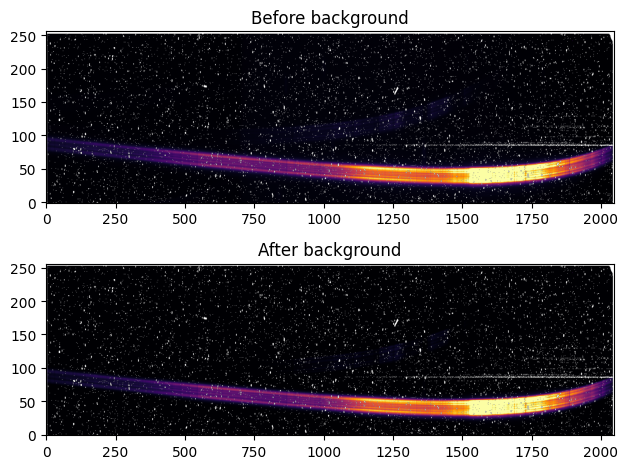

In [8]:
# remove the background
cube, err = inst.remove_background(cube, err)

# Low pass the data

In [9]:
# low pass the data
cube, err = inst.low_pass_filter(cube, err)

15:41:36.79│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_cube_bkgrnd2.fits
15:41:36.80│ Reading temporary file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_initial_err_bkgrnd2.fits


## Patch isolated bad pixels

In [10]:
# for each slice of the cube, isolated bad pixels are interpolated with the
# value of their 4 neighbours.
cube, err = inst.patch_isolated_bads(cube, err)

15:41:37.20│ patch_isolated_bads:     we read temporary files to speed things up.  Reading:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_cleaned_isolated.fits


## Remove cosmic rays

In [11]:
# remove cosmic rays with a sigma cut
cube = inst.remove_cosmic_rays(cube)

15:41:37.58│ We remove cosmisc rays
15:41:37.59│         Calculating median of 1-sigma cube


100%|██████████| 153/153 [00:00<00:00, 402.81it/s]


# Use PASTASOSS (if required)

In [12]:
# code here

## Get the trace mask

In [13]:
# get the trace map
tracemask = inst.get_trace_mask()

15:42:10.13│ Getting the trace mask


## Differential 1/f correction

In [14]:
cube, med, transit_invsout = inst.clean_1f(cube, err, tracemask)

15:42:10.16│ We read temporary files to speed things up.
15:42:10.17│         Reading:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/median.fits
15:42:10.19│         Reading:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/cleaned_cube.fits
15:42:10.38│         Reading:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/temporary_transit_in_vs_out.fits


## Recenter the trace position

15:42:30.28│ Recentering trace position
15:42:30.29│         Scan to optimize position of trace


100%|██████████| 52/52 [00:49<00:00,  1.04it/s]

15:43:20.15│ Best dx : -5 pix
15:43:20.16│ Best dy : 2 pix
15:43:20.17│         offset dy = -26.000000, gain = 0.098145 ppt
15:43:20.19│         offset dy = -25.000000, gain = 0.098031 ppt
15:43:20.20│         offset dy = -24.000000, gain = 0.099012 ppt
15:43:20.21│         offset dy = -23.000000, gain = 0.101594 ppt
15:43:20.22│         offset dy = -22.000000, gain = 0.106125 ppt
15:43:20.23│         offset dy = -21.000000, gain = 0.113067 ppt
15:43:20.24│         offset dy = -20.000000, gain = 0.124878 ppt
15:43:20.25│         offset dy = -19.000000, gain = 0.143577 ppt
15:43:20.26│         offset dy = -18.000000, gain = 0.168390 ppt
15:43:20.27│         offset dy = -17.000000, gain = 0.197410 ppt
15:43:20.28│         offset dy = -16.000000, gain = 0.230333 ppt
15:43:20.29│         offset dy = -15.000000, gain = 0.264944 ppt
15:43:20.30│         offset dy = -14.000000, gain = 0.298270 ppt
15:43:20.31│         offset dy = -13.000000, gain = 0.328128 ppt
15:43:20.33│         offset dy 

15:43:20.36│         offset dy = -9.000000, gain = 0.442444 ppt
15:43:20.37│         offset dy = -8.000000, gain = 0.470969 ppt
15:43:20.38│         offset dy = -7.000000, gain = 0.498688 ppt
15:43:20.39│         offset dy = -6.000000, gain = 0.525255 ppt
15:43:20.40│         offset dy = -5.000000, gain = 0.552437 ppt
15:43:20.41│         offset dy = -4.000000, gain = 0.582976 ppt
15:43:20.42│         offset dy = -3.000000, gain = 0.616664 ppt
15:43:20.43│         offset dy = -2.000000, gain = 0.648548 ppt
15:43:20.44│         offset dy = -1.000000, gain = 0.679416 ppt
15:43:20.45│         offset dy = 0.000000, gain = 0.707914 ppt
15:43:20.46│         offset dy = 1.000000, gain = 0.726537 ppt
15:43:20.47│         offset dy = 2.000000, gain = 0.730603 ppt
15:43:20.48│         offset dy = 3.000000, gain = 0.720569 ppt
15:43:20.50│         offset dy = 4.000000, gain = 0.698049 ppt
15:43:20.51│         offset dy = 5.000000, gain = 0.667740 ppt
15:43:20.52│         offset dy = 6.000000, gai

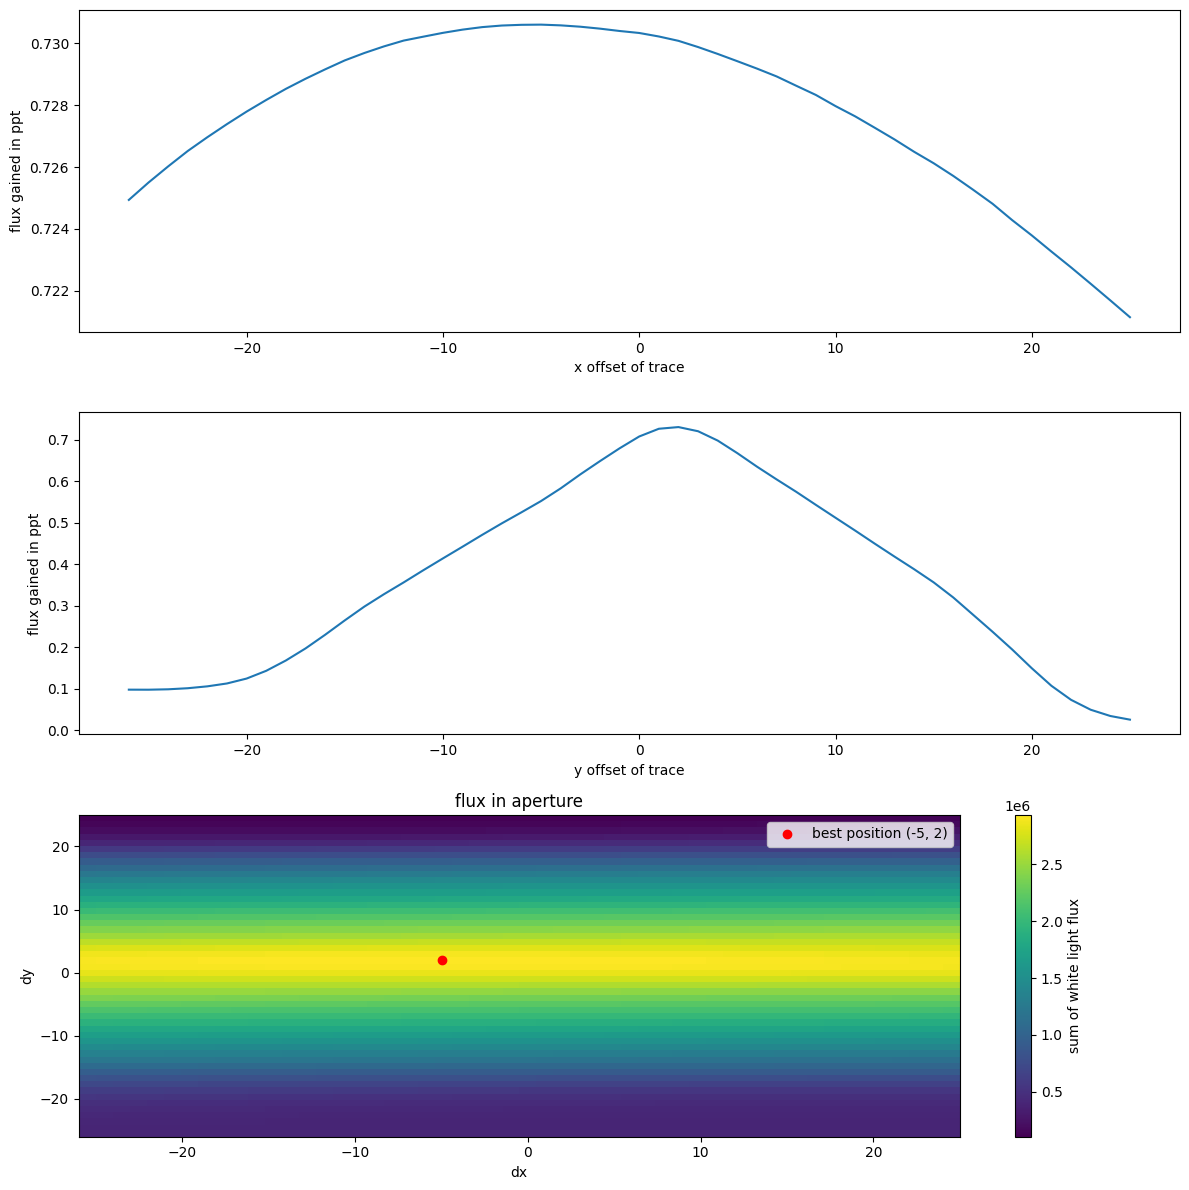

15:43:21.47│ Getting the trace mask


In [16]:
tracemask = inst.recenter_trace_position(tracemask, med)

## PCA Analysis

Note turn this off with 

```
SOSSISSE.WLC.LMODEL.FIT_PCA = False
```

In [15]:
# construct the principal component model from the out of transit domain
# using pca (we deal with not fitting the PCA inside)
pcas = inst.fit_pca(cube, err, med, tracemask)

15:42:10.40│ WLC.LMODEL.FIT_PCA=False  WLC.LMODEL.FIT_N_PCA=0Not fitting with PCA


## Linear reconstruction

08:55:38.30│ We find the gradients
08:55:38.43│ Plotting graph: derivatives.png
08:55:38.72│ Plotting graph: derivatives.pdf


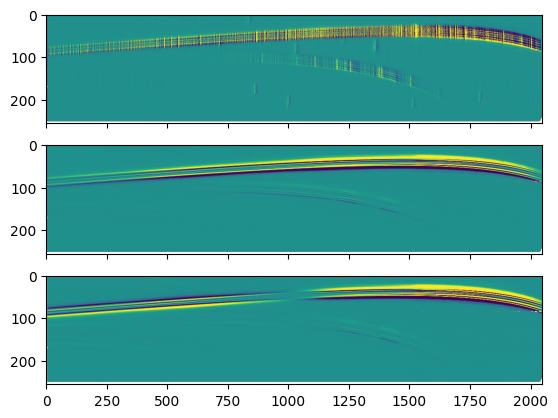

100%|██████████| 31712/31712 [00:11<00:00, 2815.25it/s]

08:55:53.18│ Plotting graph: masking_order0.png


08:55:53.42│ Plotting graph: masking_order0.pdf


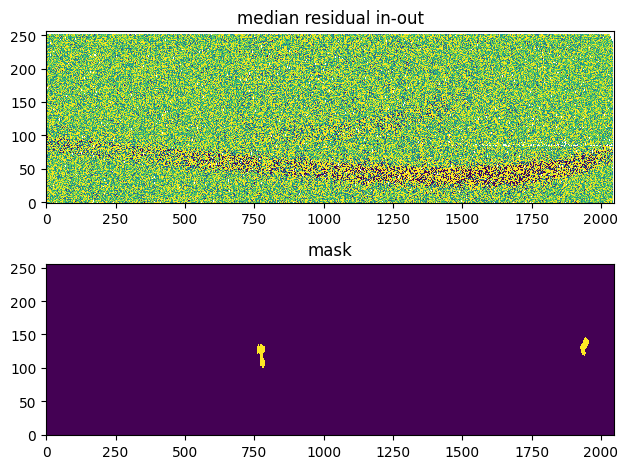

08:55:54.12│ Linear recon of trace model


  0%|          | 0/153 [00:00<?, ?it/s]

08:55:57.41│ Plotting graph: sample_frame0.png
08:55:58.22│ Plotting graph: sample_frame0.pdf


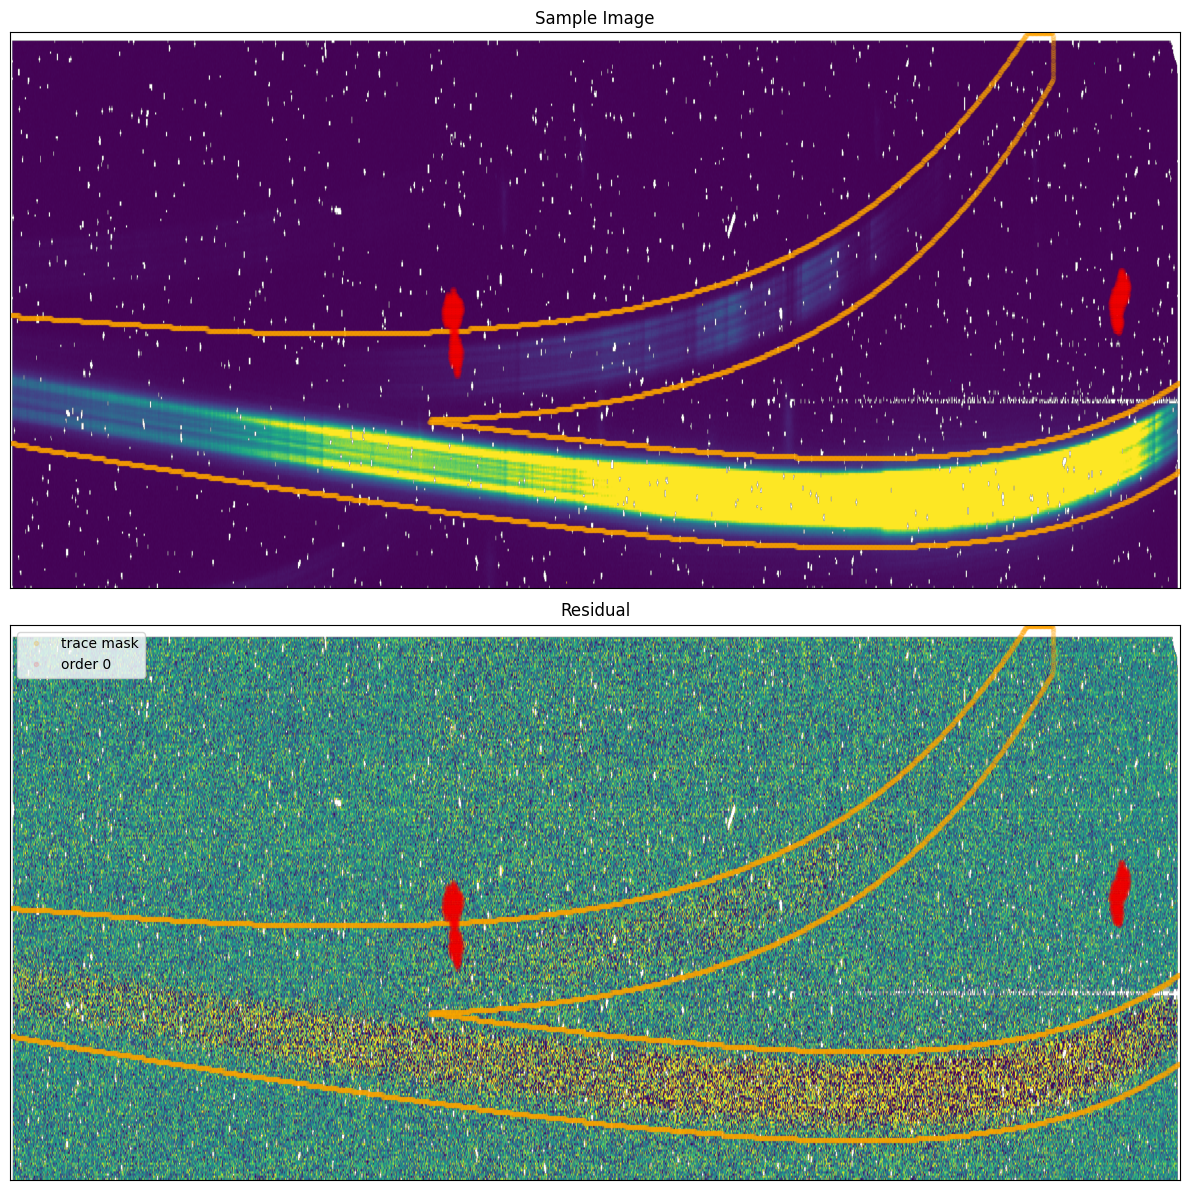

100%|██████████| 153/153 [00:24<00:00,  6.18it/s]


08:56:18.99│ Plotting graph: aperture_correction.png
08:56:19.15│ Plotting graph: aperture_correction.pdf


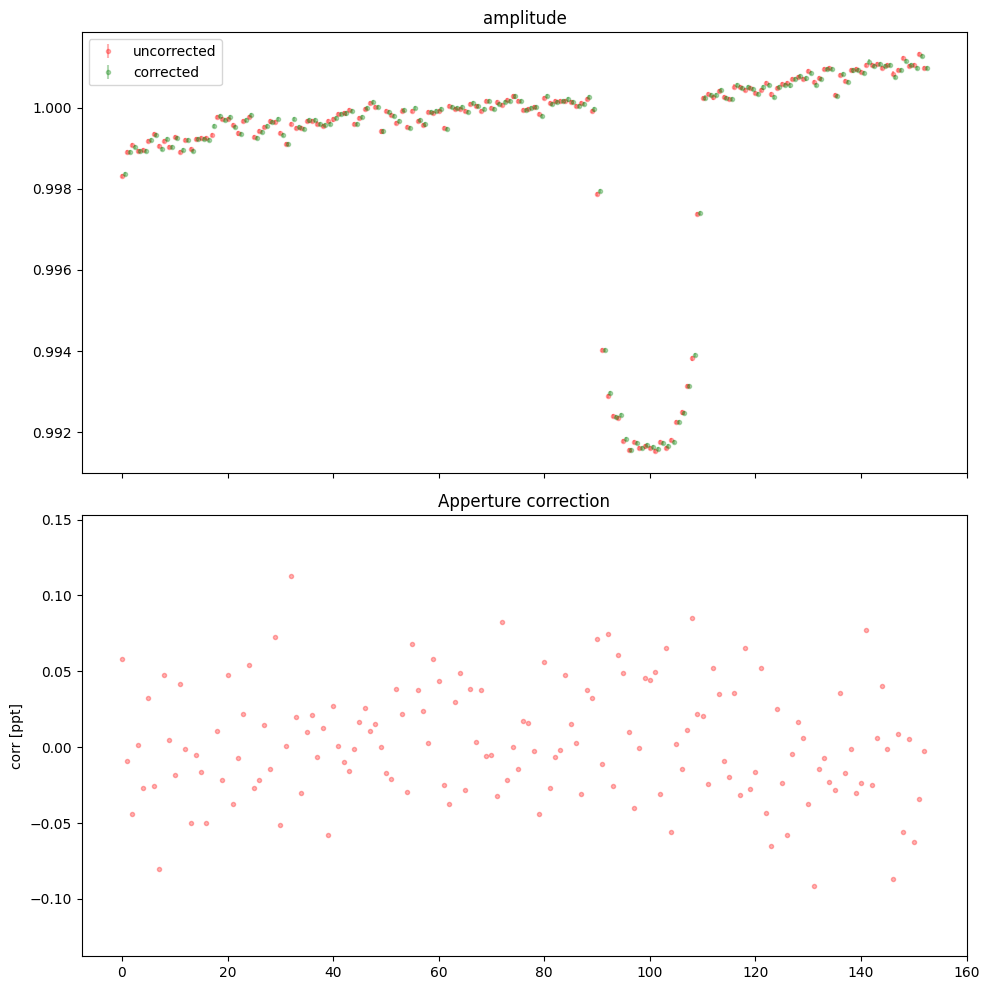

In [ ]:
# get the gradients
dx, dy, rotxy, ddy, med_clean = inst.get_gradients(med)
# set up the mask for trace position
mask_out = inst.get_mask_trace_pos(med, tracemask)
mask_trace_pos, x_order0, y_order0, x_trace_pos, y_trace_pos = mask_out

# setup the linear reconstruction vector based on the input parameters
lvector = inst.setup_linear_reconstruction(med, dx, dy, rotxy, ddy,
                                           pcas)
# -----------------------------------------------------inst--------------------
# find the best linear combination of scale/dx/dy/rotation from lvector
# amps is a vector with the amplitude of all 4 fitted terms
# amps[0] -> amplitude of trace
# amps[1] -> dx normalized on reference trace
# amps[2] -> dy normalized on reference trace
# amps[3] -> rotation (in radians) normalized on reference trace
# amps[4] -> 2nd derivative in y [if option activated]
# -------------------------------------------------------------------------
amp_out = inst.apply_amp_recon(cube, err, med, mask_trace_pos,
                               lvector, x_trace_pos, y_trace_pos,
                               x_order0, y_order0)
# get outputs of apply_amp_recon
ltable, lrecon, valid_cube = amp_out

## Transit part

Section needs better name

In [18]:
# -------------------------------------------------------------------------
# At this point we can look at the transit
inst.define_transit_ints(ltable)
# -------------------------------------------------------------------------
# normalize the trace but a normalization factor
ltable = inst.normalize_sum_trace(ltable)
# -------------------------------------------------------------------------
# per pixel baseline
if inst.params['WLC.GENERAL.PER_PIXEL_BASELINE_CORRECTION']:
    misc.printc('Performing per-pixel baseline subtraction', 'info')
    cube = inst.per_pixel_baseline(cube, valid_cube)
# -------------------------------------------------------------------------
# print the rms baseline for all methods
for method in inst.get_rms_baseline():
    # calculate the rms for this method
    rms_method = inst.get_rms_baseline(ltable['amplitude'], method=method)
    # print this
    msg = '{0}, rms = {1:.1f}ppm'.format(method, rms_method * 1e6)
    misc.printc(msg, 'number')
# -------------------------------------------------------------------------
# get the effective wavelength
photo_weighted_mean, energy_weighted_mean = inst.get_effective_wavelength()

08:56:19.45│ Performing per-pixel baseline subtraction
08:56:19.61│ Correcting the per pixel baseline


100%|██████████| 2048/2048 [02:06<00:00, 16.24it/s]

08:58:25.83│         Mid transit[1] frame used: 100
08:58:25.84│         RMS[1][before]: 0.325
08:58:25.85│         RMS[1][after]: 0.326
08:58:25.87│ naive_sigma, rms = 810.8ppm
08:58:25.88│ linear_sigma, rms = 172.3ppm


08:58:25.90│ lowpass_sigma, rms = 166.3ppm
08:58:25.91│ quadratic_sigma, rms = 161.0ppm
08:58:25.92│ Getting the trace mask
08:58:25.96│ Full domain included, parameter GENERAL.WLC_DOMAIN not defined
08:58:25.97│ Energy-weighted mean:   1.411 um
08:58:25.98│ Photon-weighted mean:   1.520 um


## Save and plot the linear recon results

08:58:26.00│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/errormap.fits


08:58:26.22│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/residual.fits
08:58:26.41│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/temporary/recon.fits
08:58:26.60│ Saving table to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/other/stability.csv
08:58:26.96│ Plotting graph: stability.png
08:58:27.29│ Plotting graph: stability.pdf


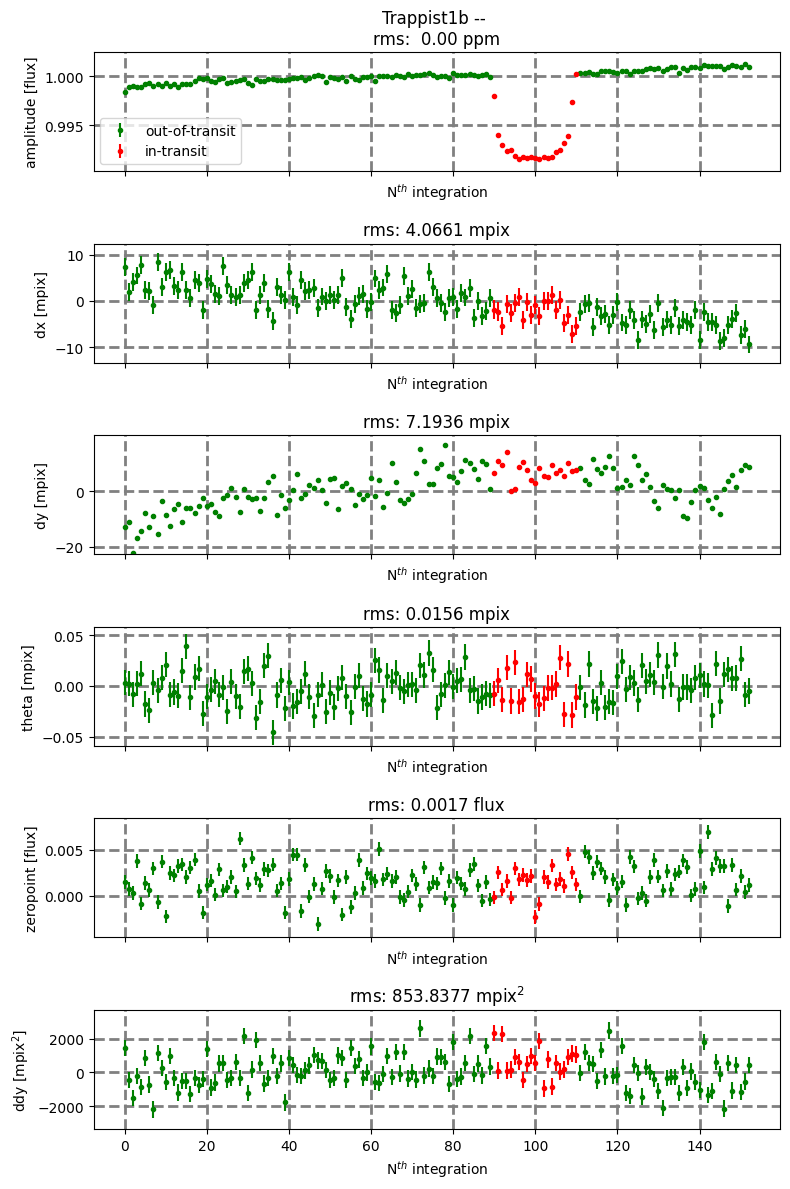

08:58:28.07│ Plotting graph: transit.png
08:58:28.17│ Plotting graph: transit.pdf


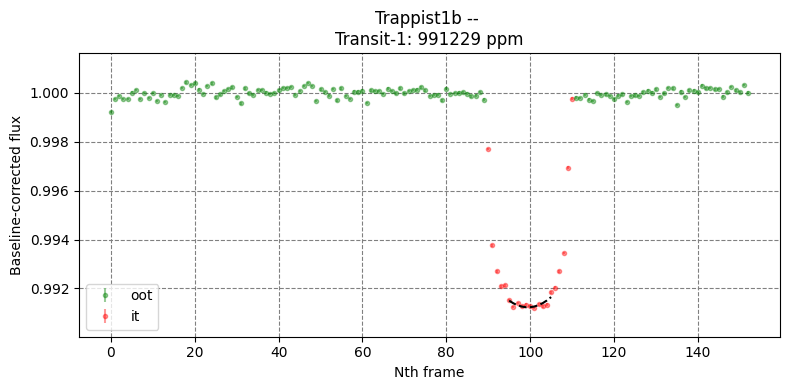

In [19]:
# =========================================================================
# write files
# =========================================================================
inst.save_wlc_results(cube, err, lrecon, ltable)
# =========================================================================
# Plots and Summary HTML
# =========================================================================
# plot the stability plot
plots.plot_stability(inst, ltable)
# -------------------------------------------------------------------------
# plot the transit plot
plots.plot_transit(inst, ltable)
# -------------------------------------------------------------------------
# write the yaml file to html
io.summary_html(inst.params)

## Spectral extraction setup

In [20]:
# get parameters from instrumental parameters
objname = inst.params['INPUTS.OBJECTNAME']
# print the white light curve splash
print(misc.art('Spectral timeseries ' + objname, 'blue', 'CYAN'))
# -------------------------------------------------------------------------
# load temporary filenames (should be run before science starts)
inst.define_filenames()
# -------------------------------------------------------------------------
# plot / save storage
storage = dict()
# get the trace orders
trace_orders = inst.get_trace_orders()


        ╔══════════════════════════════════════════════════════════════════════════════════════╗
        ║ ╔═╗┌─┐┌─┐┌─┐┌┬┐┬─┐┌─┐┬     ┌┬┐┬┌┬┐┌─┐┌─┐┌─┐┬─┐┬┌─┐┌─┐   ╔╦╗┬─┐┌─┐┌─┐┌─┐┬┌─┐┌┬┐ ┐ ┌┐  ║
        ║ ╚═╗├─┘├┤ │   │ ├┬┘├─┤│      │ ││││├┤ └─┐├┤ ├┬┘│├┤ └─┐    ║ ├┬┘├─┤├─┘├─┘│└─┐ │  │ ├┴┐ ║
        ║ ╚═╝┴  └─┘└─┘ ┴ ┴└─┴ ┴┴─┘    ┴ ┴┴ ┴└─┘└─┘└─┘┴└─┴└─┘└─┘    ╩ ┴└─┴ ┴┴  ┴  ┴└─┘ ┴ ─┴─└─┘ ║
        ╚══════════════════════════════════════════════════════════════════════════════════════╝



## Processing trace order loop

This is done for each order, you could remove the for loop and just set the
trace order individually
```
trace_order = 1
```

08:58:28.39│ Processing trace order 1
08:58:28.41│ We find the gradients
08:58:28.55│ Plotting graph: derivatives.png
08:58:28.84│ Plotting graph: derivatives.pdf


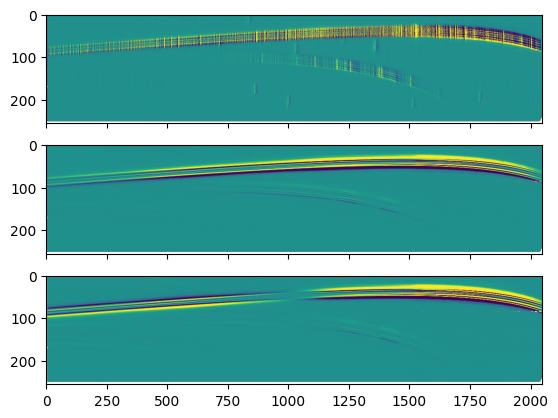

08:58:29.98│ Plotting graph: sed_Trappist1b_ord1.png
08:58:30.06│ Plotting graph: sed_Trappist1b_ord1.pdf


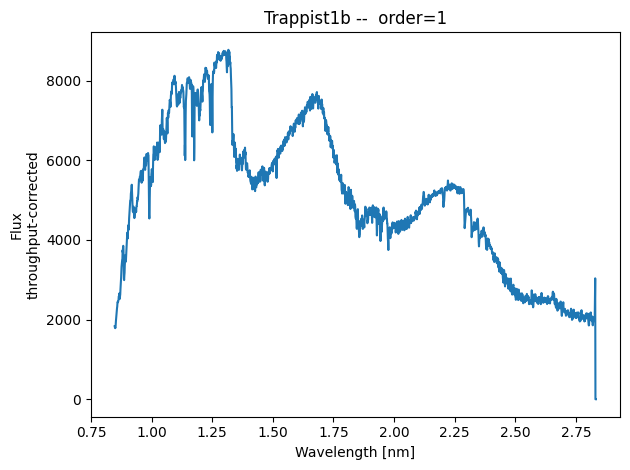

08:58:30.21│ Getting the trace mask


100%|██████████| 31712/31712 [00:11<00:00, 2783.64it/s]


08:58:43.58│ Plotting graph: masking_order0.png
08:58:43.83│ Plotting graph: masking_order0.pdf


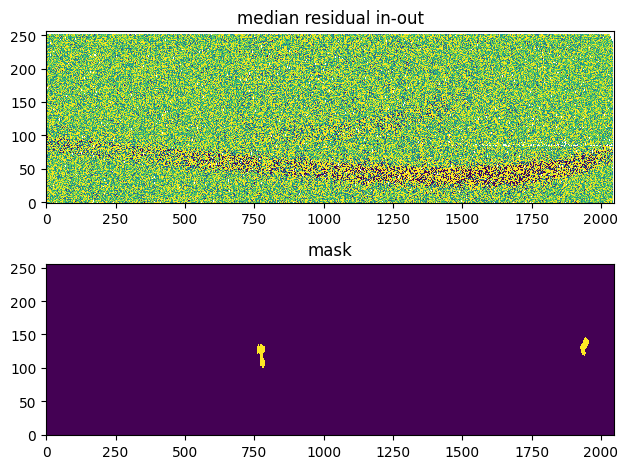

100%|██████████| 31712/31712 [00:11<00:00, 2772.58it/s]


08:58:57.51│ Plotting graph: masking_order0.png
08:58:57.74│ Plotting graph: masking_order0.pdf


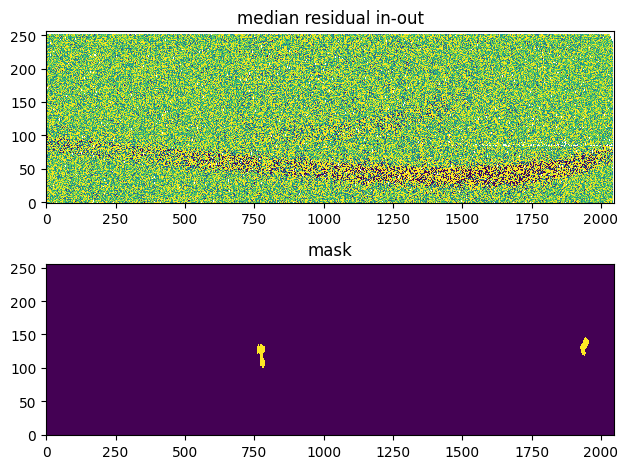

100%|██████████| 153/153 [00:00<00:00, 18055.50it/s]

08:58:58.18│ Finding the ratio of residuals to the trace



100%|██████████| 153/153 [00:00<00:00, 223.89it/s]


08:58:59.78│ Saving table to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/other/sed_Trappist1b_ord1.csv
08:59:00.91│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/fits/residual_no_grey_ord1.fits
08:59:00.93│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/fits/residual_grey_ord1.fits
08:59:00.95│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/fits/spectra_ord1.fits
08:59:00.97│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/fits/wavelength_ord1.fits
08:59:00.98│ Saving table to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470

08:59:01.14│ Saving table to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/other/tspec_ord_1_bin20.csv
08:59:01.17│ Processing trace order 2
08:59:01.18│ We find the gradients
08:59:01.32│ Plotting graph: derivatives.png
08:59:01.64│ Plotting graph: derivatives.pdf


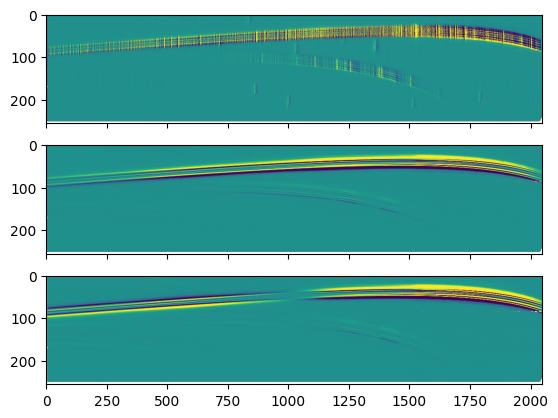

08:59:02.88│ Plotting graph: sed_Trappist1b_ord2.png
08:59:03.71│ Plotting graph: sed_Trappist1b_ord2.pdf


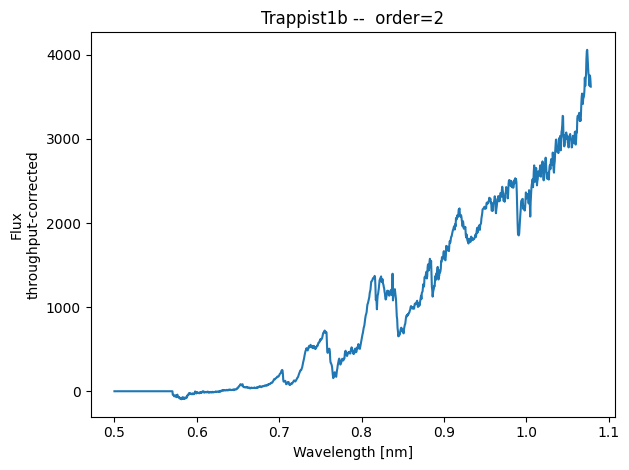

08:59:03.89│ Getting the trace mask


100%|██████████| 31712/31712 [00:11<00:00, 2779.74it/s]


08:59:17.52│ Plotting graph: masking_order0.png
08:59:17.77│ Plotting graph: masking_order0.pdf


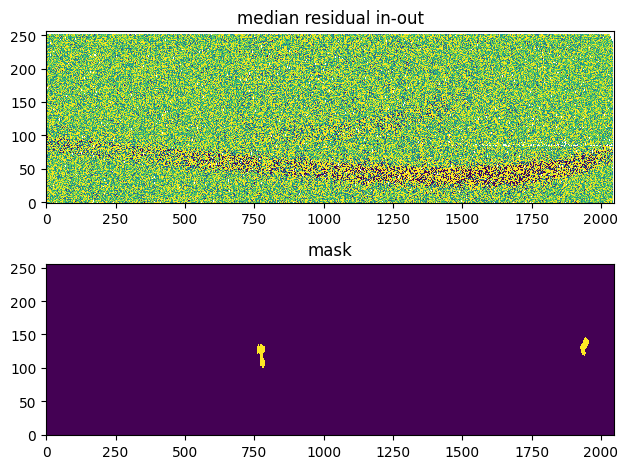

100%|██████████| 31712/31712 [00:11<00:00, 2745.74it/s]


08:59:31.51│ Plotting graph: masking_order0.png
08:59:31.75│ Plotting graph: masking_order0.pdf


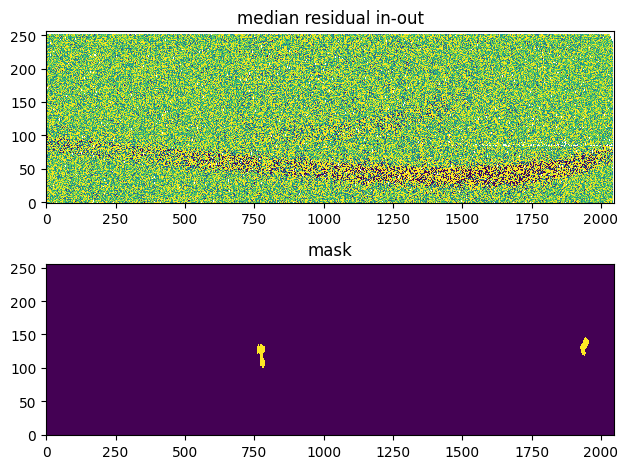

100%|██████████| 153/153 [00:00<00:00, 18178.25it/s]

08:59:32.19│ Finding the ratio of residuals to the trace



100%|██████████| 153/153 [00:00<00:00, 263.59it/s]


08:59:33.63│ Saving table to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/other/sed_Trappist1b_ord2.csv
08:59:33.65│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/fits/residual_no_grey_ord2.fits
08:59:33.68│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/fits/residual_grey_ord2.fits
08:59:33.69│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/fits/spectra_ord2.fits


08:59:33.71│ Saving data to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/fits/wavelength_ord2.fits
08:59:33.72│ Saving table to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/other/tspec_ord2.csv
08:59:33.74│ Saving table to file:
           | /scratch3/jwst/pogos-data/data/sossisse/JWST.NIRISS.SOSS/Trappist1b/SID-00017472301470485360-MF6R/other/tspec_ord_2_bin20.csv


In [21]:
# loop around trace orders
for trace_order in trace_orders:
    # print progress
    misc.printc('Processing trace order {0}'.format(trace_order), 'alert')
    # ---------------------------------------------------------------------
    # load data for this trace order
    indata = inst.load_input_spec_data(trace_order)
    med, dx, dy, rotxy, ddy, med_clean, residual, err = indata[:8]
    recon, ltable, posmax, throughput, wavegrid = indata[8:]
    # ---------------------------------------------------------------------
    # create the SED
    sp_sed = inst.create_sed(med, residual, wavegrid, posmax, throughput,
                             med_clean, trace_order)
    # ---------------------------------------------------------------------
    # load the model (and deal with masking order zero if required)
    model = inst.load_model(recon, med)
    # ---------------------------------------------------------------------
    # spectrum is the ratio of the residual to the trace model
    spec, spec_err = inst.ratio_residual_to_trace(model, err, residual,
                                                  posmax)
    # ---------------------------------------------------------------------
    # remove the out-of-transit trend on the spectrum
    if inst.params['SPEC_EXT.REMOVE_TREND']:
        spec = inst.remove_trend_spec(spec)
    # -----------------------------------------------------------------
    # reshape the amplitudes into an image
    amp_image = np.repeat(np.array(ltable['amplitude']), spec.shape[1])
    amp_image = amp_image.reshape(spec.shape)
    # add this gray component onto the spectrum
    spec2 = spec + amp_image
    # ---------------------------------------------------------------------
    # remove the out-of-transit trend on the photometric time series
    if inst.params['SPEC_EXT.REMOVE_TREND']:
        ltable = inst.remove_trend_phot(spec, ltable)
    # ---------------------------------------------------------------------
    # compute or set transit depth
    transit_depth = inst.get_transit_depth(ltable)
    # ---------------------------------------------------------------------
    # get the in-transit spectrum
    isout = inst.intransit_spectrum(spec, spec_err)
    spec_in, spec_err_in, spec_err_out = isout
    # ---------------------------------------------------------------------
    # bin the data by RESOLUTION_BIN
    wave_bin, flux_bin, flux_bin_err = inst.bin_spectrum(wavegrid,
                                                         spec_in,
                                                         spec_err_in)
    # ---------------------------------------------------------------------
    # push into storage for outside loop
    storage = general.trace_storage(storage, trace_order, wavegrid, sp_sed,
                                    throughput, spec, spec_err, ltable, spec2,
                                    spec_in, spec_err_in, transit_depth, 
                                    wave_bin, flux_bin, flux_bin_err)
    # ---------------------------------------------------------------------
    inst.save_spe_results(storage[trace_order], trace_order)

## Spectral extraction plots and saving

08:59:33.91│ Plotting graph: sed_Trappist1b.png
08:59:34.03│ Plotting graph: sed_Trappist1b.pdf


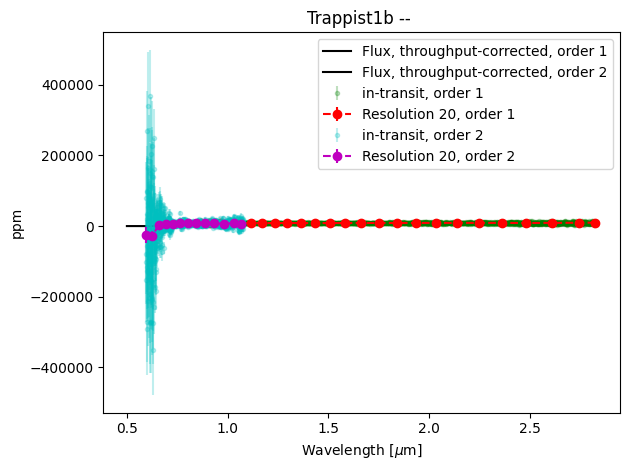

08:59:34.41│ Converting to Eureka format
08:59:34.42│ Processing order 1
08:59:34.43│ Sorting in decreasing wavelength order
08:59:34.44│ Reading raw file(s) to get time array
08:59:36.83│ Processing order 2
08:59:36.84│ Sorting in decreasing wavelength order
08:59:36.85│ Reading raw file(s) to get time array


In [22]:
# plot the SED
plots.plot_full_sed(inst, storage)
# -------------------------------------------------------------------------
# convert sossisse to eureka products
inst.to_eureka(storage)
# -------------------------------------------------------------------------
# write the yaml file to html
io.summary_html(inst.params)